In [37]:
import sys
sys.path.insert(0, '..')

import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import app.optimization
importlib.reload(app.optimization)
from app.optimization import CourseOptimizer
from app.course import Course
from app.database import CourseDatabase

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

In [43]:
# ── Load course and segment ──
db = CourseDatabase()
courses = db.conn.execute(
    "SELECT course_id, course_name, total_distance_km, total_elevation_gain_m, course_type FROM courses"
).fetchall()

print("Available courses:")
for i, c in enumerate(courses):
    print(f"  {i}: {c['course_name']} ({c['course_type']}) - {c['total_distance_km']:.1f}km, {c['total_elevation_gain_m']:.0f}m")

# Choose course and segment
COURSE_INDEX = 1
selected_course = courses[COURSE_INDEX]
course_data = db.get_course(selected_course['course_id'])

# Use processed_data (has cumulative_distance); fall back to raw_gps_data
if course_data['processed_data']:
    course_df = pd.DataFrame(course_data['processed_data'])
    course = Course(course_df, skip_processing=True)
else:
    course_df = pd.DataFrame(course_data['raw_gps_data'])
    course = Course(course_df)



course.gradient_bearing_segmentation(
    uphill_threshold=2.0, downhill_threshold=-2.0,
    bearing_change_threshold=60.0, min_segment_distance=300
)

course.auto_segmentation(max_clusters=8)

#course.equal_segmentation(4)

aggregated_segments = course.course_segments

print(f"\nCourse: {course_data['course_name']}")
print(f"Points: {len(course.df)}, Distance: {course.df['cumulative_distance'].max()/1000:.2f} km")
print(f"Segments: {len(aggregated_segments)}")

Available courses:
  0: Test Course for Integration (test_course) - 1.6km, 71m
  1: Pedal till ya puke (strava_segment) - 11.2km, 136m
  2: NF 4832 Climb (strava_segment) - 9.8km, 326m
  3: Flat Training Loop (sample_course) - 10.8km, 86m
  4: Mauna Kea Summit (sample_course) - 71.5km, 4387m
Created 9 contiguous segments:
  Seg 0: 4.37km, -0.0%, flat, Σ|bearing|=2702°
  Seg 1: 2.25km, -0.1%, flat, Σ|bearing|=1772°
  Seg 2: 0.47km, +8.3%, uphill, Σ|bearing|=251°
  Seg 3: 0.08km, -0.1%, flat, Σ|bearing|=42°
  Seg 4: 0.68km, -3.4%, downhill, Σ|bearing|=183°
  Seg 5: 1.06km, -0.2%, flat, Σ|bearing|=859°
  Seg 6: 1.03km, +4.7%, uphill, Σ|bearing|=1764°
  Seg 7: 0.09km, -2.7%, downhill, Σ|bearing|=8°
  Seg 8: 1.21km, -3.3%, downhill, Σ|bearing|=441°


/Users/chris/code/pace_yourself/app/course.py:783: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bearing_boundary = df['bearing_change_significant'] & ~df['bearing_change_significant'].shift(1).fillna(False)



Course: Pedal till ya puke
Points: 984, Distance: 11.23 km
Segments: 8


/Users/chris/code/pace_yourself/.venv/lib/python3.11/site-packages/sklearn/cluster/_agglomerative.py:586: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


In [44]:
# ── Rider parameters + optimizer ──
RIDER_CONFIG = {
    'weight': 85,          # kg (rider + bike + gear)
    'critical_power': 266, # watts
    'w_prime': 20000,      # joules
    'cda': 0.32,           # m² (drops position)
    'crr': 0.004           # rolling resistance
}

optimizer = CourseOptimizer(
    critical_power=RIDER_CONFIG['critical_power'],
    w_prime=RIDER_CONFIG['w_prime']
)

print("Rider:", {k: v for k, v in RIDER_CONFIG.items()})
print(f"Optimizer: CP={optimizer.critical_power}W, W'={optimizer.w_prime}J")

Rider: {'weight': 85, 'critical_power': 266, 'w_prime': 20000, 'cda': 0.32, 'crr': 0.004}
Optimizer: CP=266W, W'=20000J


In [45]:
# ── Optimize: constant power, then variable pacing (matched W' utilization) ──

# 1) Constant power optimization
constant_power, constant_time, constant_results_df = optimizer.optimize_constant_power(
    aggregated_segments, target_w_utilization=0.85
)
constant_result = {
    'optimal_power': constant_power, 'total_time': constant_time, 'results_df': constant_results_df
}

# Measure actual W' depletion from constant power to match variable target
_, _, const_w_remaining, _ = optimizer.simulate_course_time(constant_power, aggregated_segments)
matched_w_utilization = 1 - (const_w_remaining / RIDER_CONFIG['w_prime'])

# 2) Variable pacing — same W' depletion as constant
variable_results_df, variable_time, variable_analysis = optimizer.optimize_variable_pacing(
    aggregated_segments, target_w_utilization=matched_w_utilization, aggressive_factor=1.2
)
variable_result = {
    'total_time': variable_time, 'results_df': variable_results_df, 'analysis': variable_analysis,
    'segment_powers': variable_results_df['target_power'].tolist()
}

print(f"Matched W' utilization target: {matched_w_utilization*100:.1f}%")
print(f"Constant: {constant_power:.0f}W → {constant_time/60:.2f} min")
print(f"Variable: avg {variable_results_df['target_power'].mean():.0f}W → {variable_time/60:.2f} min")
print(f"Time savings: {constant_time - variable_time:.1f}s ({(constant_time - variable_time)/constant_time*100:.1f}%)")

Optimization converged to 281W (target W' utilization: 85%)
Achieved W' utilization: 85.0% (target: 85%)
Optimizing variable pacing strategy (target W': 85%)
Initial heuristic: avg 302W, W' utilization: 75.0% (target: 85%)
Refined in 1 iterations: avg 302W, W' utilization: 75.0% (target: 85%)
Optimization converged to 281W (target W' utilization: 85%)
Achieved W' utilization: 85.0% (target: 85%)
Variable pacing complete: 18.5 min (W' utilization: 75.0%)
Matched W' utilization target: 85.0%
Constant: 281W → 18.75 min
Variable: avg 302W → 18.47 min
Time savings: 16.8s (1.5%)


Starting high-resolution simulation with 5000 points...
Course has 984 points, using all points (target: 5000)
Normalized gradient from percentage to decimal (max was 15.6%, 41% of points > 1.0)
Using original segment labels from course data (8 segments)
Assigned variable power strategy to 984 points
High-resolution simulation complete: 18.5 min with 984 points
Starting high-resolution simulation with 5000 points...
Course has 984 points, using all points (target: 5000)
Normalized gradient from percentage to decimal (max was 15.6%, 41% of points > 1.0)
Using original segment labels from course data (8 segments)
Assigned constant power: 281W to all 984 points
High-resolution simulation complete: 18.8 min with 984 points
Detailed sims: Constant 18.78 min, Variable 18.51 min, Δ 16.6s (Variable faster)
Total work: Constant 316.8 kJ, Variable 310.4 kJ
Coloring: per-segment palette (cluster segmentation, 8 segments)


/var/folders/4t/ph7592kn339630_gjktykq2h0000gn/T/ipykernel_8934/265713789.py:148: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


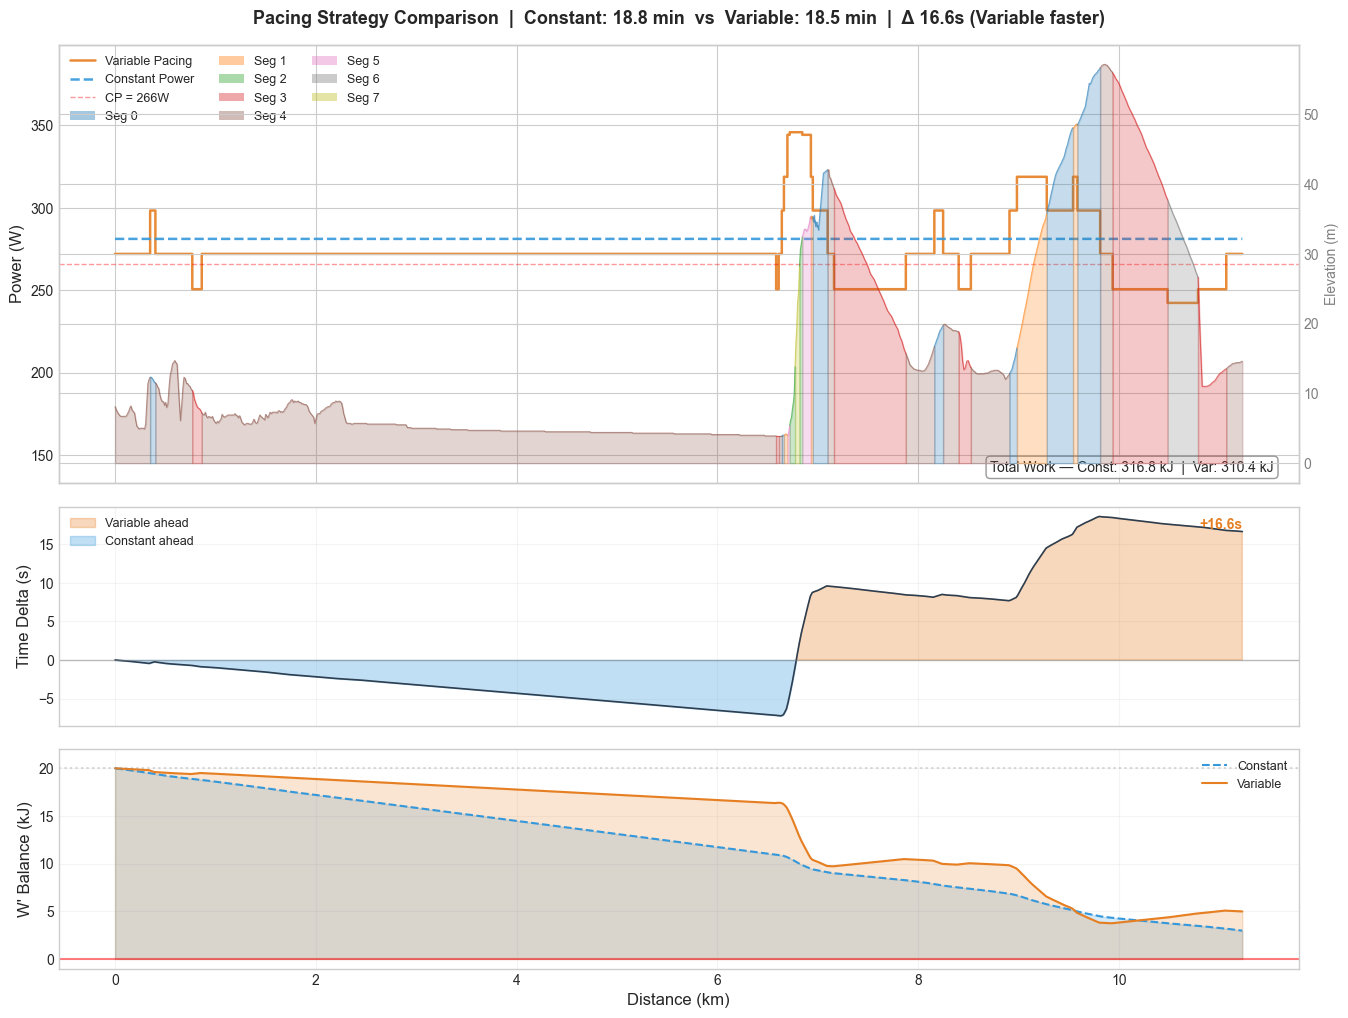

In [46]:
# ── Detailed simulations + strategy comparison visualization ──

# Run high-resolution simulations on raw GPS points
power_strategy = {i: p for i, p in enumerate(variable_result['segment_powers'])}

var_detailed, var_detailed_time, _ = optimizer.simulate_course_detailed(
    course=course, course_segments=variable_result['results_df'], power_strategy=power_strategy
)
const_detailed, const_detailed_time, _ = optimizer.simulate_course_detailed(
    course=course, course_segments=variable_result['results_df'], power_strategy=constant_result['optimal_power']
)

time_diff = const_detailed_time - var_detailed_time
faster_label = "Variable faster" if time_diff > 0 else "Constant faster"
abs_diff = abs(time_diff)

# Total work (kJ) = sum of power × time for each point
const_total_work_kj = (const_detailed['power'] * const_detailed['time']).sum() / 1000
var_total_work_kj = (var_detailed['power'] * var_detailed['time']).sum() / 1000
print(f"Detailed sims: Constant {const_detailed_time/60:.2f} min, Variable {var_detailed_time/60:.2f} min, Δ {abs_diff:.1f}s ({faster_label})")
print(f"Total work: Constant {const_total_work_kj:.1f} kJ, Variable {var_total_work_kj:.1f} kJ")

# ── Data setup ──
cum_dist_km = var_detailed['cumulative_distance'] / 1000
altitude = var_detailed['altitude']
seg_index = var_detailed['segment_index']

# Detect segmentation type from course.df's segment_terrain column.
# gradient_bearing_segmentation sets actual terrain labels (uphill/flat/downhill),
# equal_segmentation sets 'equal', auto_segmentation sets 'cluster'.
terrain_values = set()
if 'segment_terrain' in course.df.columns:
    terrain_values = set(course.df['segment_terrain'].dropna().unique())

is_terrain_segmentation = terrain_values <= {'uphill', 'flat', 'downhill'} and len(terrain_values) > 0

if is_terrain_segmentation:
    # Terrain-based: color by uphill/flat/downhill
    terrain_colors = {'uphill': '#2ecc71', 'flat': '#95a5a6', 'downhill': '#e74c3c'}
    seg_terrain_map = course.df.groupby('segment')['segment_terrain'].first().to_dict()
    point_color_key = seg_index.map(lambda s: seg_terrain_map.get(int(s), 'flat') if pd.notna(s) else 'flat')
    point_colors = point_color_key.map(terrain_colors)
    legend_patches = [
        Patch(facecolor=terrain_colors['uphill'], alpha=0.4, label='Uphill'),
        Patch(facecolor=terrain_colors['flat'], alpha=0.4, label='Flat'),
        Patch(facecolor=terrain_colors['downhill'], alpha=0.4, label='Downhill'),
    ]
    print(f"Coloring: terrain-based (gradient_bearing segmentation)")
else:
    # Segment-number-based: use a varied palette (tab10/tab20)
    unique_segs = sorted(seg_index.dropna().astype(int).unique())
    n_segs = len(unique_segs)
    cmap = plt.cm.tab20 if n_segs > 10 else plt.cm.tab10
    seg_color_map = {seg: cmap(i / max(n_segs, 1)) for i, seg in enumerate(unique_segs)}
    point_color_key = seg_index.map(lambda s: int(s) if pd.notna(s) else unique_segs[0])
    point_colors = point_color_key.map(seg_color_map)
    legend_patches = [
        Patch(facecolor=seg_color_map[seg], alpha=0.4, label=f'Seg {seg}') for seg in unique_segs
    ]
    seg_type = list(terrain_values)[0] if terrain_values else 'unknown'
    print(f"Coloring: per-segment palette ({seg_type} segmentation, {n_segs} segments)")

# ── Figure: 3 panels ──
fig, (ax_power, ax_delta, ax_wprime) = plt.subplots(
    3, 1, figsize=(16, 12), sharex=True,
    gridspec_kw={'height_ratios': [4, 2, 2], 'hspace': 0.08}
)

# Panel 1: Power profiles + elevation overlay
ax_elev = ax_power.twinx()
# Plot elevation colored by segment — iterate contiguous runs of same color
prev_color = point_colors.iloc[0]
run_start = 0
for i in range(1, len(point_colors)):
    cur_color = point_colors.iloc[i]
    if cur_color != prev_color:
        sl = slice(run_start, i + 1)  # overlap by 1 to avoid gaps
        ax_elev.fill_between(cum_dist_km.iloc[sl], altitude.iloc[sl], alpha=0.25, color=prev_color)
        ax_elev.plot(cum_dist_km.iloc[sl], altitude.iloc[sl], color=prev_color, linewidth=0.8, alpha=0.6)
        run_start = i
        prev_color = cur_color
# Final run
sl = slice(run_start, len(point_colors))
ax_elev.fill_between(cum_dist_km.iloc[sl], altitude.iloc[sl], alpha=0.25, color=prev_color)
ax_elev.plot(cum_dist_km.iloc[sl], altitude.iloc[sl], color=prev_color, linewidth=0.8, alpha=0.6)

ax_elev.set_ylabel('Elevation (m)', color='gray')
ax_elev.tick_params(axis='y', labelcolor='gray')

ax_power.step(cum_dist_km, var_detailed['power'], where='post',
              color='#e67e22', linewidth=1.8, label='Variable Pacing', alpha=0.9)
ax_power.step(cum_dist_km, const_detailed['power'], where='post',
              color='#3498db', linewidth=1.8, label='Constant Power', linestyle='--', alpha=0.9)
ax_power.axhline(y=RIDER_CONFIG['critical_power'], color='red', linestyle='--',
                 alpha=0.4, linewidth=1, label=f"CP = {RIDER_CONFIG['critical_power']}W")
ax_power.set_ylabel('Power (W)', fontsize=12)
ax_power.set_title(
    f"Pacing Strategy Comparison  |  Constant: {const_detailed_time/60:.1f} min  vs  "
    f"Variable: {var_detailed_time/60:.1f} min  |  Δ {abs_diff:.1f}s ({faster_label})",
    fontsize=13, fontweight='bold', pad=15
)
ax_power.set_ylim(bottom=RIDER_CONFIG['critical_power']*.5, top=RIDER_CONFIG['critical_power']*1.5)
power_handles, _ = ax_power.get_legend_handles_labels()
ax_power.legend(handles=power_handles + legend_patches, loc='upper left', fontsize=9, ncol=3)

# Annotate total work on the power panel
ax_power.text(
    0.98, 0.02,
    f"Total Work — Const: {const_total_work_kj:.1f} kJ  |  Var: {var_total_work_kj:.1f} kJ",
    transform=ax_power.transAxes, fontsize=10, ha='right', va='bottom',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.8)
)

# Panel 2: Time delta (variable vs constant baseline)
time_delta = const_detailed['cumulative_time'].values - var_detailed['cumulative_time'].values
ax_delta.fill_between(cum_dist_km, time_delta, 0, where=(time_delta >= 0), interpolate=True,
                      color='#e67e22', alpha=0.3, label='Variable ahead')
ax_delta.fill_between(cum_dist_km, time_delta, 0, where=(time_delta < 0), interpolate=True,
                      color='#3498db', alpha=0.3, label='Constant ahead')
ax_delta.plot(cum_dist_km, time_delta, color='#2c3e50', linewidth=1.2)
ax_delta.axhline(y=0, color='gray', linewidth=1, linestyle='-', alpha=0.5)
ax_delta.set_ylabel('Time Delta (s)', fontsize=12)
ax_delta.legend(loc='upper left', fontsize=9)
ax_delta.grid(True, alpha=0.2)
final_delta = time_delta[-1]
ax_delta.annotate(f'{final_delta:+.1f}s', xy=(cum_dist_km.iloc[-1], final_delta),
                  fontsize=10, fontweight='bold', ha='right',
                  va='bottom' if final_delta >= 0 else 'top',
                  color='#e67e22' if final_delta >= 0 else '#3498db')

# Panel 3: W' balance comparison
w_max_kj = RIDER_CONFIG['w_prime'] / 1000
ax_wprime.fill_between(cum_dist_km, const_detailed['w_remaining']/1000, alpha=0.2, color='#3498db')
ax_wprime.plot(cum_dist_km, const_detailed['w_remaining']/1000, color='#3498db',
               linewidth=1.5, label='Constant', linestyle='--')
ax_wprime.fill_between(cum_dist_km, var_detailed['w_remaining']/1000, alpha=0.2, color='#e67e22')
ax_wprime.plot(cum_dist_km, var_detailed['w_remaining']/1000, color='#e67e22',
               linewidth=1.5, label='Variable')
ax_wprime.axhline(y=w_max_kj, color='gray', linestyle=':', alpha=0.3)

ax_wprime.axhline(y=0, color='red', linewidth=1.5, alpha=0.5)
ax_wprime.set_ylabel("W' Balance (kJ)", fontsize=12)
ax_wprime.set_xlabel('Distance (km)', fontsize=12)
ax_wprime.legend(loc='upper right', fontsize=9)
ax_wprime.set_ylim(-1, w_max_kj * 1.1)
ax_wprime.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

In [42]:
# ── Quick diagnostic: what did the variable optimizer produce? ──
print("── Variable Pacing Segment Strategy ──")
vr = variable_results_df
for _, row in vr.iterrows():
    above_cp = row['target_power'] - RIDER_CONFIG['critical_power']
    zone = "ABOVE CP" if above_cp > 0 else "BELOW CP"
    print(f"  Seg {int(row['segment']):2d}: {row['target_power']:6.1f}W ({above_cp:+6.1f}W vs CP) "
          f"| grad={row['gradient']*100:+5.1f}% | dist={row['distance']/1000:.2f}km "
          f"| time={row['time']:.1f}s | W'_rem={row['w_remaining']/1000:.1f}kJ  [{zone}]")

# W' flow
above_segs = vr[vr['target_power'] > RIDER_CONFIG['critical_power']]
below_segs = vr[vr['target_power'] <= RIDER_CONFIG['critical_power']]
w_spent = above_segs['w_used_segment'].sum()
w_recov = sum((RIDER_CONFIG['critical_power'] - r['target_power']) * r['time'] for _, r in below_segs.iterrows())
print(f"\nW' spent: {w_spent/1000:.1f} kJ, recovered: {w_recov/1000:.1f} kJ, net: {(w_spent-w_recov)/1000:.1f} kJ")
print(f"Final W' remaining: {vr.iloc[-1]['w_remaining']/1000:.1f} kJ → utilization: {(1-vr.iloc[-1]['w_remaining']/RIDER_CONFIG['w_prime'])*100:.1f}%")

── Variable Pacing Segment Strategy ──
  Seg  0:  273.7W (  +7.7W vs CP) | grad= -0.1% | dist=4.37km | time=401.2s | W'_rem=16.9kJ  [ABOVE CP]
  Seg  1:  273.1W (  +7.1W vs CP) | grad= -0.1% | dist=2.25km | time=205.0s | W'_rem=15.5kJ  [ABOVE CP]
  Seg  2:  341.1W ( +75.1W vs CP) | grad= +8.3% | dist=0.47km | time=94.9s | W'_rem=8.3kJ  [ABOVE CP]
  Seg  3:  273.3W (  +7.3W vs CP) | grad= -0.1% | dist=0.08km | time=6.9s | W'_rem=8.3kJ  [ABOVE CP]
  Seg  4:  249.5W ( -16.5W vs CP) | grad= -3.4% | dist=0.68km | time=46.7s | W'_rem=9.1kJ  [BELOW CP]
  Seg  5:  272.1W (  +6.1W vs CP) | grad= -0.2% | dist=1.06km | time=95.4s | W'_rem=8.5kJ  [ABOVE CP]
  Seg  6:  311.8W ( +45.8W vs CP) | grad= +4.7% | dist=1.03km | time=153.8s | W'_rem=1.4kJ  [ABOVE CP]
  Seg  7:  251.7W ( -14.3W vs CP) | grad= -2.7% | dist=0.09km | time=6.8s | W'_rem=1.5kJ  [BELOW CP]
  Seg  8:  249.8W ( -16.2W vs CP) | grad= -3.3% | dist=1.21km | time=84.2s | W'_rem=2.9kJ  [BELOW CP]

W' spent: 19.3 kJ, recovered: 2.2 kJ, n